In [6]:
import numpy as np
import pandas as pd
import os

# Load datasets
train_path = "data/ratings_train.npy"
test_path = "data/ratings_test.npy"
names_path = "data/namesngenre.npy"

ratings_train = np.load(train_path)
ratings_test = np.load(test_path)
names_genre = np.load(names_path, allow_pickle=True)

print(f"Train shape: {ratings_train.shape} (users × movies)")
print(f"Test shape:  {ratings_test.shape} (users × movies)")
print(f"Names/genre shape: {names_genre.shape}")

# Convert to pandas DataFrame for easier inspection
train_df = pd.DataFrame(ratings_train)
test_df = pd.DataFrame(ratings_test)


Train shape: (610, 4980) (users × movies)
Test shape:  (610, 4980) (users × movies)
Names/genre shape: (4980, 2)


In [7]:
names_genre

array([['Toy Story (1995)',
        'Adventure|Animation|Children|Comedy|Fantasy'],
       ['Jumanji (1995)', 'Adventure|Children|Fantasy'],
       ['Grumpier Old Men (1995)', 'Comedy|Romance'],
       ...,
       ['Elsa & Fred (2005)', 'Comedy|Drama|Romance'],
       ['Tomb Raider (2018)', 'Action|Adventure|Fantasy'],
       ['Fred Armisen: Standup for Drummers (2018)', 'Comedy']],
      shape=(4980, 2), dtype='<U158')

Running ALS on: data/ratings_train.npy
Ratings loading...
Ratings Loaded.
Original shape: (610, 4980) (users x movies)
Applying ANNLS matrix factorization with bounded optimization...
ANNLS optimization with bounded factors completed.
Final shape: (610, 4980) (users x movies)

ALS completed in 5.0s. Loading results from output.npy...
Completed ratings shape: (610, 4980) (users x movies)
Stats: min 0.0 max 5.0 mean 3.327108104549345
Preview (first 5 users x first 5 movies):
[[4.5 4.  3.5 2.5 3.5]
 [4.  3.5 3.  2.  3. ]
 [1.5 1.5 1.  1.  1. ]
 [3.5 3.5 3.  2.  3. ]
 [4.  3.5 3.  2.  3. ]]


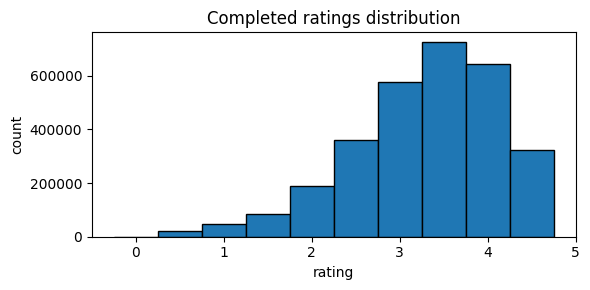

In [8]:
# Run ALS (bounded NNLS) via generate.py on the training set and preview the completed table
import os
import sys
import time
import subprocess
import numpy as np

# Determine input ratings .npy (prefer variable from earlier cells if available)
try:
    input_ratings_path = train_path  # defined earlier in the notebook
except NameError:
    input_ratings_path = "data/ratings_train.npy"

print(f"Running ALS on: {input_ratings_path}")

# Remove stale output if present
out_path = "output.npy"
if os.path.exists(out_path):
    os.remove(out_path)

start = time.time()
proc = subprocess.run(
    [sys.executable, "generate.py", "--name", input_ratings_path],
    capture_output=True,
    text=True,
)
elapsed = time.time() - start

# Show script logs
print(proc.stdout)
if proc.returncode != 0:
    print(proc.stderr)
    raise RuntimeError(f"ALS run failed with exit code {proc.returncode}")

print(f"ALS completed in {elapsed:.1f}s. Loading results from {out_path}...")
completed = np.load(out_path)
print("Completed ratings shape:", completed.shape, "(users x movies)")
print("Stats: min", completed.min(), "max", completed.max(), "mean", float(completed.mean()))

# Preview a small block
print("Preview (first 5 users x first 5 movies):")
print(np.array_str(completed[:5, :5], precision=2, suppress_small=True))

# Optional visualization: distribution of completed ratings
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(6, 3))
    bins = np.arange(-0.25, 5.25, 0.5)
    plt.hist(completed.ravel(), bins=bins, edgecolor='k')
    plt.title("Completed ratings distribution")
    plt.xlabel("rating")
    plt.ylabel("count")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Visualization skipped:", e)

In [9]:
completed


array([[4.5, 4. , 3.5, ..., 4.5, 4. , 4.5],
       [4. , 3.5, 3. , ..., 3.5, 3.5, 4. ],
       [1.5, 1.5, 1. , ..., 1.5, 1.5, 1.5],
       ...,
       [3.5, 3. , 3. , ..., 3.5, 3. , 3.5],
       [3.5, 3. , 3. , ..., 3.5, 3. , 3.5],
       [4. , 3.5, 3.5, ..., 4. , 3.5, 4. ]], shape=(610, 4980))

In [ ]:
ratings_test

In [10]:
# Compute RMSE of completed predictions against ratings_test on observed entries only
import numpy as np

# Ensure we have the completed matrix and ratings_test in memory
try:
    pred = completed
except NameError:
    pred = np.load("output.npy")

true = ratings_test

# Identify observed entries in test (non-NaN)
mask = ~np.isnan(true)
num_obs = int(mask.sum())
if num_obs == 0:
    raise ValueError("No observed entries found in ratings_test to compute RMSE.")

# Compute RMSE only where test ratings are observed
sq_err = (pred[mask] - true[mask]) ** 2
rmse = float(np.sqrt(sq_err.mean()))

print(f"Test RMSE on {num_obs} observed entries: {rmse:.4f}")

Test RMSE on 31598 observed entries: 0.9146


In [11]:
# Build an error DataFrame for observed test entries and summarize where ALS performs well/poorly
import numpy as np
import pandas as pd

# Ensure predictions and test matrix are loaded
try:
    pred = completed
except NameError:
    pred = np.load("output.npy")
true = ratings_test

mask = ~np.isnan(true)
user_idx, movie_idx = np.where(mask)
true_vals = true[mask]
pred_vals = pred[mask]

errors_df = pd.DataFrame({
    "user": user_idx,
    "movie": movie_idx,
    "true": true_vals,
    "pred": pred_vals,
})
errors_df["abs_err"] = np.abs(errors_df["pred"] - errors_df["true"]).astype(float)
errors_df["sq_err"] = (errors_df["pred"] - errors_df["true"]) ** 2

print(f"Observed test entries: {len(errors_df):,}")

# Group by true rating to see which true values are easier/harder
by_true = errors_df.groupby("true").agg(
    count=("abs_err", "size"),
    mae=("abs_err", "mean"),
    rmse=("sq_err", lambda x: float(np.sqrt(x.mean()))),
    med_abs_err=("abs_err", "median"),
).reset_index().sort_values("true")
print("\nPerformance by true rating (lower is better):")
print(by_true)

# Show best N and worst N predictions
N = 10
print(f"\nTop {N} best-predicted entries (lowest absolute error):")
print(errors_df.nsmallest(N, "abs_err"))

print(f"\nTop {N} worst-predicted entries (highest absolute error):")
print(errors_df.nlargest(N, "abs_err"))

# Keep for later visualization
errors_summary_by_true = by_true

Observed test entries: 31,598

Performance by true rating (lower is better):
   true  count       mae      rmse  med_abs_err
0   0.5    433  2.245958  2.386330          2.0
1   1.0    840  1.791667  1.945997          2.0
2   1.5    513  1.308967  1.481695          1.5
3   2.0   2307  1.049632  1.208669          1.0
4   2.5   1737  0.679620  0.842950          0.5
5   3.0   6402  0.534520  0.689095          0.5
6   3.5   4072  0.408890  0.567951          0.5
7   4.0   8403  0.451267  0.635019          0.5
8   4.5   2689  0.653961  0.836982          0.5
9   5.0   4202  0.989767  1.136402          1.0

Top 10 best-predicted entries (lowest absolute error):
    user  movie  true  pred  abs_err  sq_err
2      0     80   5.0   5.0      0.0     0.0
11     0    323   5.0   5.0      0.0     0.0
17     0    559   5.0   5.0      0.0     0.0
18     0    574   4.0   4.0      0.0     0.0
21     0    651   5.0   5.0      0.0     0.0
22     0    678   4.0   4.0      0.0     0.0
23     0    712   5.0   

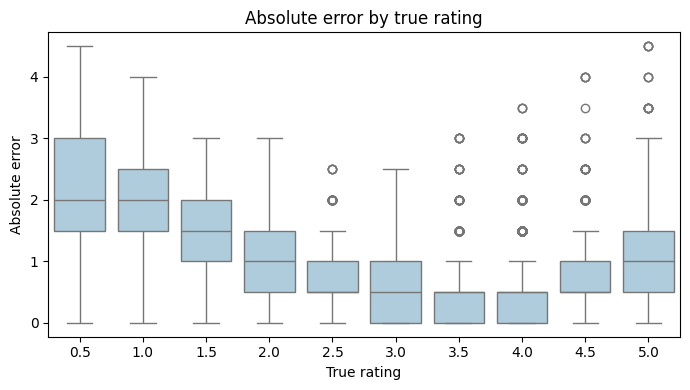

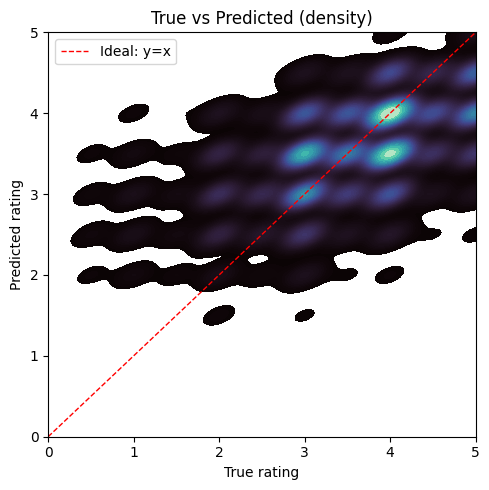

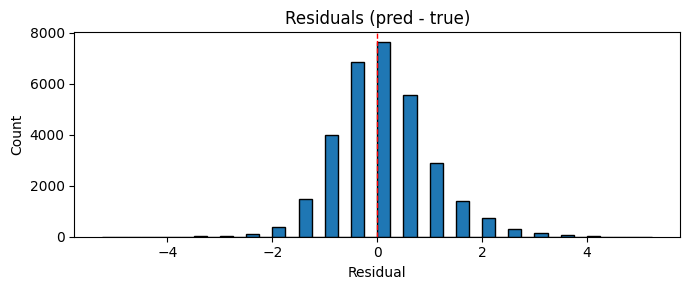

In [13]:
# Visualizations: abs error by true rating, true vs pred, residual histogram
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Boxplot of absolute error by true rating
plt.figure(figsize=(7,4))
sns.boxplot(x="true", y="abs_err", data=errors_df, color="#a6cee3")
plt.title("Absolute error by true rating")
plt.xlabel("True rating")
plt.ylabel("Absolute error")
plt.tight_layout()
plt.show()

# 2) True vs Predicted density and diagonal
plt.figure(figsize=(5,5))
sns.kdeplot(x=errors_df["true"], y=errors_df["pred"], fill=True, cmap="mako", thresh=0.05, levels=50)
lims = [0, 5]
plt.plot(lims, lims, "r--", linewidth=1, label="Ideal: y=x")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("True rating")
plt.ylabel("Predicted rating")
plt.title("True vs Predicted (density)")
plt.legend()
plt.tight_layout()
plt.show()

# 3) Residual histogram
residuals = errors_df["pred"] - errors_df["true"]
plt.figure(figsize=(7,3))
plt.hist(residuals, bins=np.arange(-5.25, 5.26, 0.25), edgecolor="k")
plt.axvline(0, color="r", linestyle="--", linewidth=1)
plt.title("Residuals (pred - true)")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [17]:
ratings_test = pd.DataFrame(ratings_test)
print("Unique true ratings in the test set:", sorted(errors_df["true"].unique()))


Unique true ratings in the test set: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


In [ ]:
# Worst-performing movies (per-movie RMSE/MAE on observed test entries), joined with titles/genres
import numpy as np
import pandas as pd

# Build mapping from movie index -> (title, genres)
# names_genre is shape (n_movies, 2) with [title, genres]
movie_meta = pd.DataFrame(names_genre, columns=["title", "genres"])  # index aligns with movie id

# Reuse errors_df built earlier; if missing, build it quickly
try:
    _ = errors_df
except NameError:
    try:
        pred = completed
    except NameError:
        pred = np.load("output.npy")
    true = ratings_test
    mask = ~np.isnan(true)
    user_idx, movie_idx = np.where(mask)
    errors_df = pd.DataFrame({
        "user": user_idx,
        "movie": movie_idx,
        "true": true[mask],
        "pred": pred[mask],
    })
    errors_df["abs_err"] = np.abs(errors_df["pred"] - errors_df["true"]).astype(float)
    errors_df["sq_err"] = (errors_df["pred"] - errors_df["true"]) ** 2

# Aggregate per movie
per_movie = errors_df.groupby("movie").agg(
    n_obs=("sq_err", "size"),
    rmse=("sq_err", lambda x: float(np.sqrt(x.mean()))),
    mae=("abs_err", "mean"),
    med_abs_err=("abs_err", "median"),
).reset_index()

# Join with metadata
per_movie = per_movie.merge(movie_meta, left_on="movie", right_index=True, how="left")

# Filter to movies with enough test ratings to be reliable
min_obs = 20  # tweak threshold as needed
worst_movies = per_movie[per_movie["n_obs"] >= min_obs].sort_values(["rmse", "n_obs"], ascending=[False, False])

top_k = 20
print(f"Worst-performing movies by RMSE (n_obs >= {min_obs}), top {top_k}:")
cols = ["movie", "title", "genres", "n_obs", "rmse", "mae", "med_abs_err"]
print(worst_movies[cols].head(top_k))